<a href="https://colab.research.google.com/github/lovkush7/NLP--P/blob/main/machineperf_ann.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [81]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [82]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [83]:
path = "/content/drive/MyDrive/ann_machine_fault_dataset.csv"

In [84]:
import pandas as pd
df =  pd.read_csv(path)

In [85]:
df.head()

,rotational_speed_rpm,load_ratio,vibration_rms,vibration_peak,kurtosis,crest_factor,axial_vibration,radial_vibration,motor_temperature_c,temperature_rise_c,acoustic_level_db,motor_current_amp,power_factor,speed_fluctuation,high_frequency_energy,machine_state
0,2023.657072,0.327035,0.326893,0.410523,3.352593,1.954819,0.174903,-0.070698,28.817619,5.662402,55.367569,2.752937,0.952334,0.601635,0.356633,normal
1,1437.687586,0.190313,0.839471,1.247190,3.333821,2.058972,0.089828,0.787459,20.845860,-0.257088,58.384610,3.499349,0.925537,1.147219,0.712677,imbalance
2,1532.041921,0.606622,0.464423,0.687698,2.254951,1.618753,-0.002494,0.013658,29.459035,6.839001,53.065455,3.901011,0.980885,0.301800,0.012924,normal
3,808.608587,0.570635,0.847419,1.507075,5.960726,2.375596,0.222822,0.693307,34.134083,10.811968,61.570771,3.617933,0.979801,0.669308,1.172057,bearing_fault
4,1867.896203,0.966476,1.153449,1.952780,3.188977,2.517570,1.342761,0.248229,43.378139,16.301323,61.351144,5.724867,0.857134,0.965361,0.484514,misalignment


In [86]:
df.shape

(12000, 16)

In [87]:
df.describe()

,rotational_speed_rpm,load_ratio,vibration_rms,vibration_peak,kurtosis,crest_factor,axial_vibration,radial_vibration,motor_temperature_c,temperature_rise_c,acoustic_level_db,motor_current_amp,power_factor,speed_fluctuation,high_frequency_energy
count,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000
mean,1549.676738,0.575555,0.732741,1.133949,3.685535,2.068708,0.373614,0.511187,33.997396,9.020142,55.310310,3.948266,0.948553,0.680998,0.507401
std,489.145315,0.244391,0.365198,0.627656,1.163369,0.379460,0.326942,0.356497,6.011960,4.536037,5.352484,0.873260,0.028184,0.531151,0.375529
min,700.257534,0.150015,-0.016705,-0.241879,0.472708,0.992209,-0.290514,-0.319710,14.340581,-4.448655,39.970709,1.654314,0.837223,-0.554851,-0.241453
25%,1124.191225,0.363149,0.418697,0.588759,2.872023,1.783761,0.170656,0.253082,29.848292,5.717302,51.242251,3.266458,0.936017,0.315149,0.205932
50%,1550.747719,0.577405,0.676926,1.021475,3.450920,2.021229,0.286419,0.412377,33.949872,8.915412,54.854755,3.942952,0.953228,0.538914,0.407802
75%,1972.172048,0.786950,1.031450,1.656990,4.291371,2.336489,0.439788,0.708263,38.013231,12.132644,59.111436,4.628853,0.967277,0.910614,0.770667
max,2399.953327,0.999959,1.803681,3.282637,8.320754,3.323102,1.760404,1.754107,63.572286,24.964775,72.806407,6.620689,1.033613,2.901999,2.061782


In [88]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   rotational_speed_rpm   12000 non-null  float64
 1   load_ratio             12000 non-null  float64
 2   vibration_rms          12000 non-null  float64
 3   vibration_peak         12000 non-null  float64
 4   kurtosis               12000 non-null  float64
 5   crest_factor           12000 non-null  float64
 6   axial_vibration        12000 non-null  float64
 7   radial_vibration       12000 non-null  float64
 8   motor_temperature_c    12000 non-null  float64
 9   temperature_rise_c     12000 non-null  float64
 10  acoustic_level_db      12000 non-null  float64
 11  motor_current_amp      12000 non-null  float64
 12  power_factor           12000 non-null  float64
 13  speed_fluctuation      12000 non-null  float64
 14  high_frequency_energy  12000 non-null  float64
 15  ma

In [89]:
df.isnull().sum()

,0
rotational_speed_rpm,0
load_ratio,0
vibration_rms,0
vibration_peak,0
kurtosis,0
crest_factor,0
axial_vibration,0
radial_vibration,0
motor_temperature_c,0
temperature_rise_c,0


In [90]:
df.duplicated().sum()

np.int64(0)

In [91]:
df['machine_state'].value_counts()

,count
machine_state,
normal,5783
bearing_fault,2422
imbalance,2038
misalignment,1757


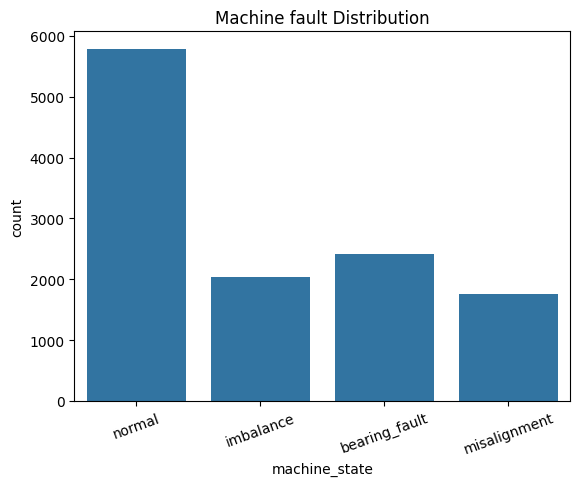

In [92]:
sns.countplot(data = df, x = 'machine_state')
plt.title("Machine fault Distribution")
plt.xticks(rotation=20)
plt.show()

In [93]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization


In [94]:
X = df.drop('machine_state', axis=1)
y = df['machine_state']

In [95]:
encoder = LabelEncoder()
y = encoder.fit_transform(y)
print(encoder.classes_)

['bearing_fault' 'imbalance' 'misalignment' 'normal']


In [96]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [97]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [98]:
model = Sequential([
    Dense(128, input_dim=X_train.shape[1], activation='tanh'),
    BatchNormalization(),
    Dropout(0.3),

    Dense(64, activation='tanh'),
    BatchNormalization(),
    Dropout(0.25),

    Dense(32, activation='tanh'),

    Dense(4, activation='softmax')
])



In [99]:
model.compile(
    optimizer= tf.keras.optimizers.RMSprop(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']

)
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 128)            │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,284 (51.89 KB)

 Trainable params: 12,900 (50.39 KB)

 Non-trainable params: 384 (1.50 KB)

In [100]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=0.00001
)

In [101]:
history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=150,
    batch_size=32,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/150
240/240 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9716 - loss: 0.1041 - val_accuracy: 0.9990 - val_loss: 0.0050 - learning_rate: 0.0010
Epoch 2/150
240/240 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9921 - loss: 0.0256 - val_accuracy: 1.0000 - val_loss: 0.0016 - learning_rate: 0.0010
Epoch 3/150
240/240 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9934 - loss: 0.0225 - val_accuracy: 0.9995 - val_loss: 0.0029 - learning_rate: 0.0010
Epoch 4/150
240/240 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9947 - loss: 0.0190 - val_accuracy: 1.0000 - val_loss: 9.7148e-04 - learning_rate: 0.0010
Epoch 5/150
240/240 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9953 - loss: 0.0164 - val_accuracy: 1.0000 - val_loss: 8.5545e-04 - learning_rate: 0.0010
Epoch 6/150
240/240 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9943 - loss: 0.0181 - val_accuracy: 0.9995 - val_loss: 0.0012 - learning_rate: 0.0010
Epoch 7/150
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9944 - 

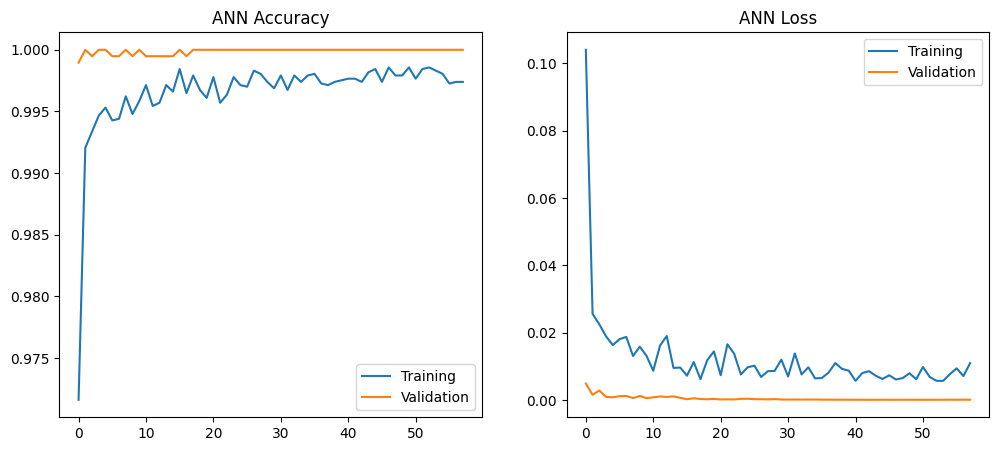

In [102]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("ANN Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("ANN Loss")
plt.legend()

plt.show()

In [103]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9996 - loss: 5.2286e-04
Test Loss: 0.0005228593945503235
Test Accuracy: 0.9995833039283752


In [104]:
from sklearn.metrics import classification_report, confusion_matrix

In [105]:
y_pred = model.predict(X_test)

y_pred_classes = np.argmax(y_pred, axis=1)

print(
    classification_report(
        y_test,
        y_pred_classes,
        target_names=encoder.classes_.astype(str)
    )
)

75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 993us/step
               precision    recall  f1-score   support

bearing_fault       1.00      1.00      1.00       484
    imbalance       1.00      1.00      1.00       408
 misalignment       1.00      1.00      1.00       351
       normal       1.00      1.00      1.00      1157

     accuracy                           1.00      2400
    macro avg       1.00      1.00      1.00      2400
 weighted avg       1.00      1.00      1.00      2400



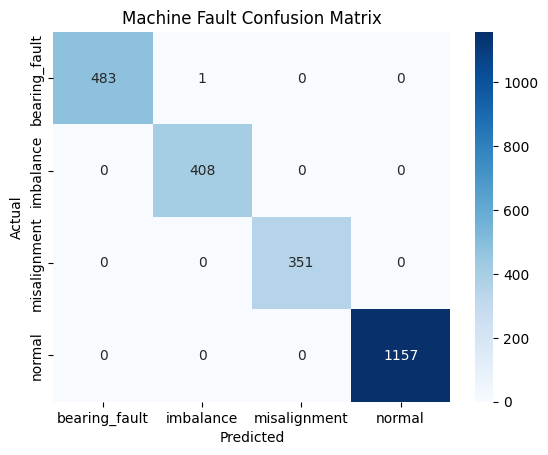

In [106]:
cm = confusion_matrix(y_test, y_pred_classes)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Machine Fault Confusion Matrix")
plt.show()

In [107]:
new_machine = pd.DataFrame([{
    "rotational_speed_rpm": 1500,
    "load_ratio": 0.65,
    "vibration_rms": 0.95,
    "vibration_peak": 1.65,
    "kurtosis": 5.5,
    "crest_factor": 2.4,
    "axial_vibration": 0.3,
    "radial_vibration": 0.9,
    "motor_temperature_c": 42,
    "temperature_rise_c": 17,
    "acoustic_level_db": 65,
    "motor_current_amp": 4.5,
    "power_factor": 0.92,
    "speed_fluctuation": 1.4,
    "high_frequency_energy": 1.1
}])

new_machine_scaled = scaler.transform(new_machine)

prediction = model.predict(new_machine_scaled)

predicted_class = np.argmax(prediction, axis=1)

print("Predicted machine state:",
      encoder.inverse_transform(predicted_class)[0])

print("Probabilities:", prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
Predicted machine state: bearing_fault
Probabilities: [[9.99694943e-01 1.86361562e-04 1.18613934e-04 1.46219179e-07]]
